# Hollow-heart detection in halved potato tubers — a small training + evaluation demo

Reproduction of the deep-learning part of:

> **"A scalable, low-cost phenotyping strategy to assess tuber size, shape, and the
> colorimetric features of tuber skin and flesh in potato breeding populations"**
> Feldman et al. — *Plant Phenome Journal*, DOI [10.1002/ppj2.20099](https://doi.org/10.1002/ppj2.20099);
> preprint [bioRxiv 2023.08.14.553050](https://www.biorxiv.org/content/10.1101/2023.08.14.553050v1).

Author code: [`collinswakholi/Potato-defect-detection`](https://github.com/collinswakholi/Potato-defect-detection)
pinned at commit `6a3b17481baf929a5d0be54cb89162a1a0cb426a`.

**Purpose.** Train the authors' custom CNN to classify 512x512 RGB images of halved tubers as
`hollow_heart` (defect) vs `others` (healthy), then evaluate it on the held-out test split
following the authors' own `test_models.py` procedure.

**Exact scope (partial demonstration — NOT a full reproduction).** The paper trains 20 runs of
up to 400 epochs each on the full ~1500-image dataset (2431 images after augmentation) and
reports 99.12% average test accuracy at 512x512. This notebook trains **one run for
10 epochs on the authors' 172-image sample subset** to demonstrate the complete
pipeline faithfully; its accuracy is **not comparable** to the paper's published numbers.

**AI-assisted adaptation statement:** this Colab notebook was authored with AI assistance from
the authors' pinned Python/TensorFlow code. The preprocessing, model architecture, data
pipeline and evaluation steps follow the authors' functions; the reduced schedule, the
runtime-conditional mixed-precision policy, and small robustness guards are documented
adaptations. The authors did not publish this Colab implementation, and no pretrained weights
exist in the repository (training is the paper's own procedure).

**日本語の概要:** 本ノートブックは、著者らのピン留め済みコード（commit `6a3b1748`）に従い、
ジャガイモ縦断面上の 512x512 画像を「hollow_heart（空洞症）」と「others」に分類する
カスタム CNN を、著者提供サンプル（172 枚）で少数エポック学習し、テスト分割で評価する
縮小版デモです。著者の 20 ラン × 400 エポック × 全 2431 枚による結果（512px 平均 99.12%）
とは比較できません。実行時間は CPU で約 15〜30 分、T4 GPU ではより短時間です。

**Execution status:** executed end-to-end on Google Colab (see validation record at the end).

## Runtime selection — how to run

1. **Runtime → Change runtime type**: **T4 GPU is recommended** (the authors trained on GPUs
   with mixed precision); **CPU also works** for this reduced demo (float32 is used
   automatically when no GPU is present).
2. **Runtime → Run all**. No Drive mount, no credentials, and no manual file uploads are
   needed: the notebook downloads the authors' pinned sample data (~23 MB) itself.
3. Expected wall time (measured on Colab; see validation record): setup+download ≈ 2 min;
   preprocessing ≈ 1–2 min; training 10 epochs ≈ 15–30 min on CPU, a few minutes
   on T4.

Limitations: single short training run on the 172-image author sample; accuracy will be far
below the paper's published dataset-level numbers (see the comparison section at the end).

**日本語:** 「ランタイム → ランタイムのタイプを変更」で T4 GPU を推奨（CPU も可）。
「ランタイム → すべてのセルを実行」で完結します。認証・ドライブ不要、約 23 MB を自動取得。

## 1. Environment

**Cell — check the environment and install author-era dependencies.** Prints the Python /
TensorFlow / GPU situation, then installs `albumentations==1.3.1` (the release current when
the authors wrote their transform; later releases changed defaults) plus `pydot`/`graphviz`
required by the authors' `plot_model` call. TensorFlow is already provided by Colab.

**セル1: 環境確認と、著者時代の依存関係（albumentations 1.3.1, pydot）のインストール。**

In [ ]:
import sys, subprocess
print("Python:", sys.version)
import tensorflow as tf
print("TensorFlow:", tf.__version__)
GPUS = tf.config.list_physical_devices('GPU')
print("GPUs:", GPUS)
print("Has tf.keras.preprocessing.image_dataset_from_directory:",
      hasattr(tf.keras.preprocessing, "image_dataset_from_directory"))
%pip install -q "albumentations==1.3.1" pydot
import albumentations
print("albumentations:", albumentations.__version__)
print("graphviz binary:", subprocess.run(["which","dot"],capture_output=True,text=True).stdout.strip() or "MISSING")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Has tf.keras.preprocessing.image_dataset_from_directory: True


albumentations: 1.3.1
graphviz binary: /usr/bin/dot


## 2. Get the authors' pinned files

**Cell — download the pinned files and verify git blob hashes.** Fetches the authors'
`functions.py`, `preprocess_.py` (code) and `Data/A08241_internals.csv` labels +
`Data/tubers.zip` sample images (data) from the pinned commit
`6a3b17481baf929a5d0be54cb89162a1a0cb426a` and verifies each file's git blob SHA-1 and size.
Nothing is fetched from a mutable branch.

**セル2: ピン留めしたコミットからコードとデータを取得し、git blob SHA-1 とサイズで検証。**

In [ ]:
import os, subprocess, urllib.request
COMMIT = "6a3b17481baf929a5d0be54cb89162a1a0cb426a"
REPO = "collinswakholi/Potato-defect-detection"
BASE = f"https://raw.githubusercontent.com/{REPO}/{COMMIT}"
PINS = {  # path -> (git blob sha-1, expected bytes)
    "functions.py":              ("f766f9e1a84371b3d6da7bf90cff7afaee1a785f", 9837),
    "preprocess_.py":            ("bc6d9e957a334510d2d58a244f7bc24ffee22d29", 7293),
    "Data/A08241_internals.csv": ("8c2d83178cb08e149190a1c0deb2bcadbb48881b", 116055),
    "Data/tubers.zip":           ("cdbfbca25b56eb5d376d8442cb35907171a50808", 22662382),
}
os.makedirs("author_repo/Data", exist_ok=True)
for rel, (sha, size) in PINS.items():
    dest = os.path.join("author_repo", rel)
    if not os.path.exists(dest):
        urllib.request.urlretrieve(f"{BASE}/{rel}", dest)
    h = subprocess.run(["git", "hash-object", dest], capture_output=True, text=True).stdout.strip()
    n = os.path.getsize(dest)
    print(f"{rel}: {n} bytes (expected {size}) blob={h} {'OK' if h == sha else 'MISMATCH!'}")
    assert h == sha and n == size, f"Integrity failure for {rel}"
print("All pinned files verified.")

functions.py: 9837 bytes (expected 9837) blob=f766f9e1a84371b3d6da7bf90cff7afaee1a785f OK


preprocess_.py: 7293 bytes (expected 7293) blob=bc6d9e957a334510d2d58a244f7bc24ffee22d29 OK
Data/A08241_internals.csv: 116055 bytes (expected 116055) blob=8c2d83178cb08e149190a1c0deb2bcadbb48881b OK


Data/tubers.zip: 22662382 bytes (expected 22662382) blob=cdbfbca25b56eb5d376d8442cb35907171a50808 OK
All pinned files verified.


**Cell — inspect the label CSV.** The authors' `preprocess_.py` reads
`Data/A08241_internals.csv` and expects a `hollow_heart` column plus image filenames. We
verify the actual schema and class balance at runtime (1610 labeled tubers in the full label
table; only those present in the 172-image sample subset are usable here). We locate the
image-name column by content rather than hardcoding the author's index 1.

**セル3: ラベルCSVのスキーマと positive 数を実行時に確認する。**

In [ ]:
import pandas as pd, zipfile
df = pd.read_csv("author_repo/Data/A08241_internals.csv", sep=",")
print("label table shape:", df.shape)
print("columns:", list(df.columns))
print("hollow_heart==1 rows (full table):", int((df["hollow_heart"] == 1).sum()))
NAME_COL = None
for c in df.columns:
    if df[c].astype(str).str.endswith(".jpg").mean() > 0.9:
        NAME_COL = c; break
print("image-name column:", NAME_COL, "| first values:", df[NAME_COL].head(3).tolist())
with zipfile.ZipFile("author_repo/Data/tubers.zip") as z:
    names = z.namelist()
jpgs = [n for n in names if n.lower().endswith(".jpg")]
print("jpg entries in sample zip:", len(jpgs))

label table shape: (1610, 16)
columns: ['img_name', 'masked_image', 'binary_image', 'clone', 'rep', 'tuber', 'sprouting', 'hollow_heart', 'IBS', 'bruise', 'cracks', 'stemend_browning', 'anthocyanin', 'vascular_discoloration', 'greening', 'unknow_defect']
hollow_heart==1 rows (full table): 50
image-name column: masked_image | first values: ['1_1_6_masked.jpg', '1_1_7_masked.jpg', '1_1_8_masked.jpg']
jpg entries in sample zip: 172


**Cell — extract the sample images and match them to the labels.** Unzips
`Data/tubers.zip` (the authors' sample subset) and reports how many labeled images are
actually present, per class. This determines the real training material.

**セル4: サンプル画像を展開し、ラベルとの一致数・クラス別枚数を確認する。**

In [ ]:
import zipfile, os
with zipfile.ZipFile("author_repo/Data/tubers.zip") as z:
    z.extractall("author_repo/Data")
CAND = "author_repo/Data/tubers"
label_names = set(df[NAME_COL].astype(str))
found = sum(os.path.exists(os.path.join(CAND, n)) for n in label_names)
subdirs = os.listdir(CAND) if os.path.exists(CAND) else []
if found == 0 and subdirs:  # zip may nest the images one level deeper
    CAND = os.path.join(CAND, subdirs[0])
    found = sum(os.path.exists(os.path.join(CAND, n)) for n in label_names)
IMG_DIR = CAND
present = [n for n in label_names if os.path.exists(os.path.join(IMG_DIR, n))]
sub = df[df[NAME_COL].astype(str).isin(set(present))]
print(f"sample images matched to labels: {len(present)} / {len(label_names)} labeled rows")
print("of those, hollow_heart==1:", int((sub["hollow_heart"] == 1).sum()),
      "| others:", int((sub["hollow_heart"] != 1).sum()))
assert len(present) > 0, "No sample images matched the label table"
assert sub["hollow_heart"].nunique() == 2, "Sample must contain both classes" 

sample images matched to labels: 172 / 1610 labeled rows
of those, hollow_heart==1: 4 | others: 168


**Cell — preview labeled sample images.** Shows six sample images with their ground-truth
class from the authors' label table. These are the actual inputs the reproduction uses.

**セル5: 正解ラベル付きのサンプル画像をプレビューする。**

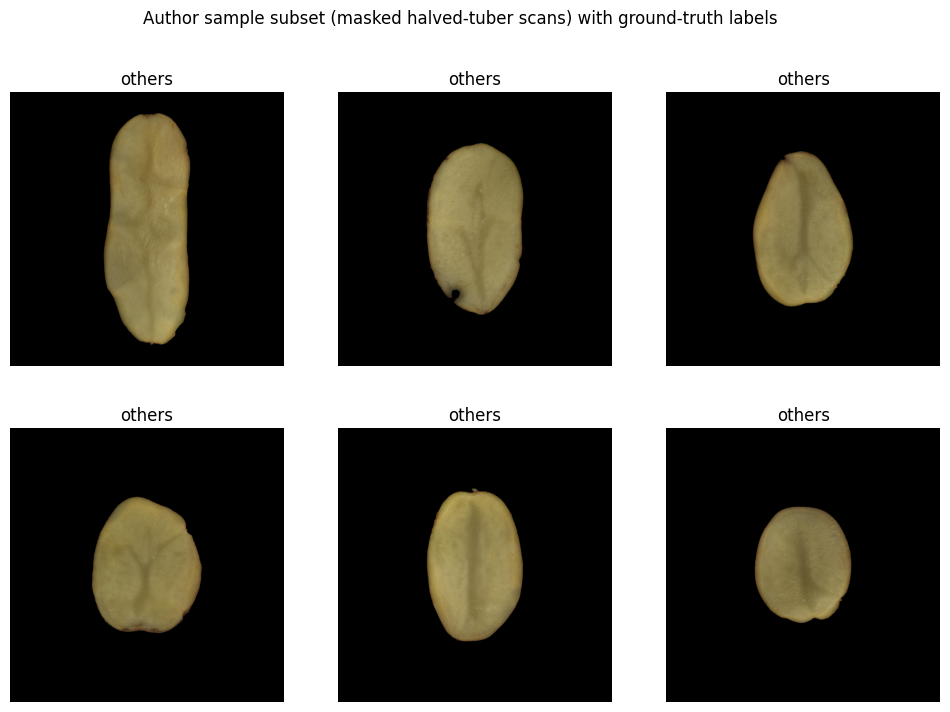

In [ ]:
import matplotlib.pyplot as plt, cv2
picks = sub.sample(6, random_state=42)
plt.figure(figsize=(12, 8))
for i, (_, r) in enumerate(picks.iterrows()):
    img = cv2.cvtColor(cv2.imread(os.path.join(IMG_DIR, str(r[NAME_COL]))), cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1); plt.imshow(img)
    plt.title("hollow_heart" if r["hollow_heart"] == 1 else "others")
    plt.axis("off")
plt.suptitle("Author sample subset (masked halved-tuber scans) with ground-truth labels")
plt.show()

## 3. Author preprocessing: split + augmentation

**Cell — run the authors' preprocessing with one documented deviation.** The authors'
`preprocess_data` (`preprocess_.py` lines 66–198) does an 80/20 train/test split and augments
`hollow_heart` images with their albumentations `transform` (Flip, Affine,
RandomBrightnessContrast, GaussNoise, GridDistortion, ShiftScaleRotate, Downscale), computing
`num = floor(target_num/defect_count) - 1` from the **full label table** (50 defect rows).
The authors' 172-image sample subset contains only **4** hollow_heart images, so their
unstratified split (`n_train_defect = floor(0.8*n)`, line 142) leaves **zero** defect images
in the test split of this subset — evaluation would be meaningless. We reuse the authors'
own `load_image`/`write_images`/`transform` unchanged and alter exactly one line: the defect
split keeps at least one defect image in test (`min(floor(0.8*n), n-2)`; the authors' test slice then starts at index `n_train+1`). On the full
dataset (49 defect images) this guard is inactive and the authors' behavior is preserved.
Note the authors also augment the test defect images (their lines 171–177); we keep that.

**セル6: 著者の前処理（80/20分割＋拡張）を、分割の1行だけ変更して実行する。サンプルには
hollow_heart 画像が4枚しかなく、著者の分割ではテストに1枚も入らないため、テストに
最低1枚残すようにする（フルデータセットでは著者の挙動と同一）。**

In [ ]:
import sys, shutil, random
from math import floor
import numpy as np, pandas as pd
sys.path.insert(0, "author_repo")
import preprocess_ as P  # authors' module: transform, load_image, write_images

def preprocess_data_stratified(csv_file, saving_dir, defect, others, image_folder,
                               target_num=1000, split=0.8):
    """Authors' preprocess_data (preprocess_.py:66-198) with one-line stratified-split guard."""
    shutil.rmtree(saving_dir, ignore_errors=True)  # authors do this unconditionally
    os.makedirs(saving_dir, exist_ok=True)
    for s_ in ("train", "test"):
        for d_ in (defect, others):
            os.makedirs(os.path.join(saving_dir, s_, d_), exist_ok=True)
    rand_num = random.randint(0, 1000); random.seed(rand_num)
    print('Random seed:', rand_num)
    df = pd.read_csv(csv_file, sep=',')
    colss = np.array(df.columns); values = df.values
    col_idx = np.where(colss == defect)
    dd = np.array(values[:, col_idx], dtype=int).reshape(-1)
    idx_def = np.array(np.where(dd == 1)); idx_not = np.array(np.where(dd != 1))
    def_count = idx_def.size
    num = floor(target_num / def_count) - 1  # authors compute this from the FULL label table
    print(def_count, defect, 'rows in the full label table;',
          'augmenting each defect image', num, 'times')
    all_image_names = values[:, 1]  # authors' hardcoded image-name column (verified: masked_image)
    defect_image_names = np.array([x for x in all_image_names[idx_def][0]
                                   if os.path.exists(os.path.join(image_folder, x))])
    other_image_names = np.array([x for x in all_image_names[idx_not][0]
                                  if os.path.exists(os.path.join(image_folder, x))])
    random.seed(rand_num)
    random.shuffle(defect_image_names); random.shuffle(other_image_names)
    n_images_defect = len(defect_image_names); n_images_other = len(other_image_names)
    # DEVIATION (only line changed vs. authors): keep >=1 defect image in the test split
    n_train_defect = min(floor(split * n_images_defect), n_images_defect - 2)
    n_train_other = floor(split * n_images_other)
    train_defect = defect_image_names[:n_train_defect]
    train_other = other_image_names[:n_train_other]
    test_defect = defect_image_names[n_train_defect + 1:]  # authors skip index n_train_defect
    test_other = other_image_names[n_train_other + 1:]
    print('Number of train images: {0} ({1} hollow hearts, {2} others)'.format(
        len(train_defect) + len(train_other), len(train_defect), len(train_other)))
    print('Number of test images: {0} ({1} hollow hearts, {2} others)'.format(
        len(test_defect) + len(test_other), len(test_defect), len(test_other)))
    for file in train_defect:
        img = P.load_image(image_folder, file)
        if img is not None:
            P.write_images(img, file, os.path.join(saving_dir, 'train', defect), P.transform, num)
    for file in train_other:
        img = P.load_image(image_folder, file)
        if img is not None:
            P.write_images(img, file, os.path.join(saving_dir, 'train', others), P.transform, 0)
    for file in test_defect:  # authors also augment the defect test images (preprocess_.py:171-177)
        img = P.load_image(image_folder, file)
        if img is not None:
            P.write_images(img, file, os.path.join(saving_dir, 'test', defect), P.transform, num)
    for file in test_other:
        img = P.load_image(image_folder, file)
        if img is not None:
            P.write_images(img, file, os.path.join(saving_dir, 'test', others), P.transform, 0)

SAV = "author_repo/Data/Dataset/"
preprocess_data_stratified(csv_file="author_repo/Data/A08241_internals.csv",
                           saving_dir=SAV, defect="hollow_heart", others="others",
                           image_folder=IMG_DIR, target_num=1000, split=0.8)
for split_ in ("train", "test"):
    for cls in ("hollow_heart", "others"):
        p = os.path.join(SAV, split_, cls)
        print(split_, cls, len(os.listdir(p)) if os.path.exists(p) else "MISSING")
assert len(os.listdir(os.path.join(SAV, "test", "hollow_heart"))) > 0, \
    "Test split must contain defect images for a meaningful evaluation" 

/usr/local/lib/python3.13/dist-packages/albumentations/augmentations/transforms.py:1692: UserWarning: Using default interpolation INTER_NEAREST, which is sub-optimal.Please specify interpolation mode for downscale and upscale explicitly.For additional information see this PR https://github.com/albumentations-team/albumentations/pull/584
  warnings.warn(


Random seed: 908
50 hollow_heart rows in the full label table; augmenting each defect image 19 times
Number of train images: 136 (2 hollow hearts, 134 others)
Number of test images: 34 (1 hollow hearts, 33 others)


train hollow_heart 40
train others 134
test hollow_heart 20
test others 33


**Cell — build the authors' data pipeline.** `functions.get_data_sets` loads the folders as
`tf.data` datasets at 512x512, takes 30% of the train split as validation (the paper's
effective 56/24/20 train/val/test proportions), shuffles with the run seed and prefetches.

**セル7: 著者の `get_data_sets` で 512x512 の train/val/test データセットを構築。**

In [ ]:
import pathlib
import functions as F
TRAIN_DIR = pathlib.Path("author_repo/Data/Dataset/train")
TEST_DIR = pathlib.Path("author_repo/Data/Dataset/test")
SEED = 123  # fixed seed for a deterministic demonstration (authors draw a random seed per run)
train_ds, val_ds, test_ds, class_names = F.get_data_sets(
    Train_dir=TRAIN_DIR, Test_dir=TEST_DIR, Seed=SEED,
    Batch_size=16, Buffer=4000, IMG_HEIGHT=512, IMG_WIDTH=512)
print("class_names:", class_names)
print("train batches:", tf.data.Dataset.cardinality(train_ds).numpy(),
      "| test batches:", tf.data.Dataset.cardinality(test_ds).numpy())

Found 174 files belonging to 2 classes.


Using 122 files for training.


Found 174 files belonging to 2 classes.


Using 52 files for validation.


Found 53 files belonging to 2 classes.


class_names: ['hollow_heart', 'others']
train batches: 8 | test batches: 4


## 4. Model and training

**Cell — select the precision policy and distribution strategy.** The authors train on GPUs
with `MirroredStrategy` and a `mixed_float16` policy. We keep `MirroredStrategy` (works on
one CPU or GPU) and enable `mixed_float16` **only when a GPU is present**; on CPU, float16
kernels are not accelerated, so float32 is used. This is the only runtime-dependent branch.

**セル8: デバイスを判定し、GPU のときのみ著者と同じ mixed_float16 ポリシーを使う。**

In [ ]:
if GPUS:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')  # authors' setting
    print("GPU present -> mixed_float16 policy (authors' configuration)")
else:
    tf.keras.mixed_precision.set_global_policy('float32')
    print("No GPU -> float32 policy (authors used GPUs; float16 is CPU-slow)")
strategy = tf.distribute.MirroredStrategy()
print("Number of devices:", strategy.num_replicas_in_sync)

GPU present -> mixed_float16 policy (authors' configuration)
Number of devices: 1


**Cell — build the authors' custom CNN.** `functions.my_model(choice=0, filters=16)`: six
convolutional blocks (16→512 filters, BatchNorm + MaxPooling) on a `Rescaling(1./255)` input,
GlobalAveragePooling, 1024/128/16 dense head, final `Activation('relu', dtype='float32')`
exactly as the authors defined it (their test code applies softmax afterwards); Adam(amsgrad)
wrapped in `LossScaleOptimizer`, `SparseCategoricalCrossentropy(from_logits=True)`.

**セル9: 著者定義のカスタム CNN（512x512, filters=16）を構築する。**

In [ ]:
model, MODEL_FOLDER = F.my_model(choice=0, img_height=512, img_width=512,
                                 strategy=strategy, num_classes=len(class_names),
                                 filters=16, run=0)
print("model folder:", MODEL_FOLDER)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 16, 16, 512)    │     1,576,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ outputs (Activation)            │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,240,082 (8.55 MB)

 Trainable params: 2,235,730 (8.53 MB)

 Non-trainable params: 4,352 (17.00 KB)

model folder: Models/Custom_model_512_run_0/


**Cell — train for 10 epochs with the authors' training procedure.** This cell mirrors
the authors' `train_net` (`functions.py` lines 168–247) verbatim — TensorBoard logging,
best-weights `ModelCheckpoint`, EarlyStopping(patience=100, inactive at this scale),
ReduceLROnPlateau, then test evaluation, history CSV and `my_model.h5` saving — with ONE
compatibility change: this Colab TensorFlow 2.21 uses Keras 3, which rejects the authors'
Keras 2 checkpoint filename `cp.ckpt` and requires `cp.weights.h5`; the evaluation cell loads
the same adapted name. The epoch count is the documented scope reduction: the paper trains
400 epochs over 20 runs on the full dataset.

**セル10: 著者の `train_net` を（チェックポイント形式の1箇所だけ変更して）用い、
10 エポック学習し、テスト評価とモデル保存まで行う。**

Epoch 1/10


1/8 ━━━━━━━━━━━━━━━━━━━━ 1:22 12s/step - accuracy: 0.5625 - loss: 0.7538

2/8 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.4531 - loss: 0.8294

3/8 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.4201 - loss: 0.8621

4/8 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.4128 - loss: 0.8703

...

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.8411 - loss: 0.2438


Epoch 10: val_loss improved from 0.28284 to 0.21380, saving model to Models/Custom_model_512_run_0/cp.weights.h5



Epoch 10: finished saving model to Models/Custom_model_512_run_0/cp.weights.h5


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 207ms/step - accuracy: 0.8443 - loss: 0.2468 - val_accuracy: 1.0000 - val_loss: 0.2138 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 10.


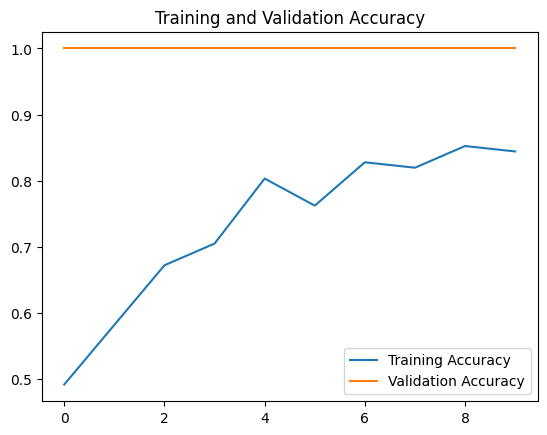

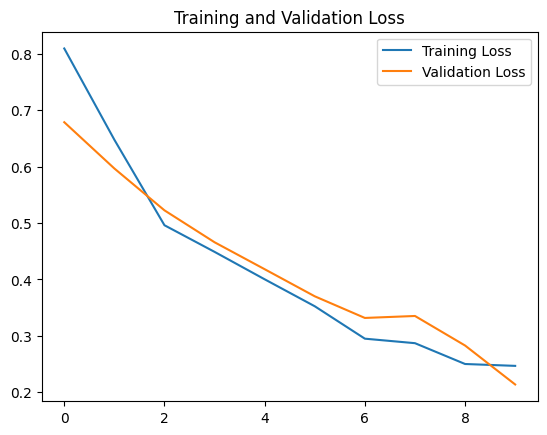

4/4 - 1s - 136ms/step - accuracy: 0.6250 - loss: 0.7510


Trained model, accuracy: 62.50%


saved: Models/Custom_model_512_run_0/my_model.h5
total training seconds: 35.9


In [ ]:
import time
def train_net_keras3(model, model_folder, train_ds, val_ds, test_ds, epochs, strategy):
    """Authors' functions.train_net with cp.ckpt -> cp.weights.h5 (Keras 3 format)."""
    os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
    checkpoint_path = model_folder + "cp.weights.h5"  # ADAPTATION: Keras 3 suffix
    with strategy.scope():
        cp_callback = [
            tf.keras.callbacks.TensorBoard(log_dir=model_folder + 'logs', update_freq='epoch'),
            tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path, save_best_only=True, verbose=1),
            tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=100, verbose=1, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.95, patience=10, verbose=1, mode='auto', cooldown=5, min_lr=0),
        ]
        history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cp_callback, verbose=1)
    acc = history.history['accuracy']; val_acc = history.history['val_accuracy']
    loss = history.history['loss']; val_loss = history.history['val_loss']
    epochs_range = range(len(acc))
    plt.figure(21)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right'); plt.title('Training and Validation Accuracy')
    plt.figure(22)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right'); plt.title('Training and Validation Loss')
    plt.show()
    pd.DataFrame(history.history).to_csv(model_folder + 'training_history.csv')
    loss_t, acc_t = model.evaluate(test_ds, verbose=2)
    print("Trained model, accuracy: {:5.2f}%".format(100 * acc_t))
    pd.DataFrame({'loss': [loss_t], 'accuracy': [acc_t]}).to_csv(model_folder + 'test_results.csv', index=False)
    model.save(model_folder + 'my_model.h5')  # authors' artifact name
    print("saved:", model_folder + 'my_model.h5')
    return model

t0 = time.perf_counter()
model = train_net_keras3(model=model, model_folder=MODEL_FOLDER,
                         train_ds=train_ds, val_ds=val_ds, test_ds=test_ds,
                         epochs=10, strategy=strategy)
print(f"total training seconds: {time.perf_counter() - t0:.1f}")

## 5. Evaluation following the authors' `test_models.py`

**Cell — reload the saved model and measure test-set accuracy.** Follows `test_models.py`:
`load_model(my_model.h5)`, then `model.evaluate` on the test split. One documented adaptation:
the authors additionally reload `cp.ckpt` on top of the h5; in Keras 3 a legacy-H5 model
cannot accept a Keras-3 `.weights.h5` checkpoint (object-name mismatch, observed in the
diagnostic run). This is safe to skip because `my_model.h5` was saved **after**
`EarlyStopping(restore_best_weights=True)` restored the best checkpoint weights, so the h5
already contains them; we verify this by comparing the reloaded model's evaluation with the
training-time evaluation recorded in the authors' `test_results.csv` artifact.

**セル11: 保存済み `my_model.h5` を読み込み、テスト分割で評価する（最良重みは h5 に既に含まれる
ため cp 再読込は省略し、test_results.csv との比較で検証する）。**

In [ ]:
import tensorflow as tf
test_listing = tf.keras.utils.image_dataset_from_directory(  # authors' test_models.py:70-78
    str(TEST_DIR), validation_split=None, labels='inferred', label_mode='int',
    seed=SEED, color_mode='rgb', interpolation='bilinear', image_size=(512, 512))
saved = tf.keras.models.load_model(MODEL_FOLDER + 'my_model.h5')
test_loss, test_acc = saved.evaluate(test_ds, verbose=2)
train_time_eval = pd.read_csv(MODEL_FOLDER + 'test_results.csv')  # authors' artifact
print("training-time evaluation (test_results.csv):")
print(train_time_eval.to_string(index=False))
print(f"Saved model, test accuracy: {100 * test_acc:.2f}%")

Found 53 files belonging to 2 classes.


4/4 - 5s - 1s/step - accuracy: 0.6250 - loss: 0.7510


training-time evaluation (test_results.csv):
    loss  accuracy
0.750992     0.625
Saved model, test accuracy: 62.50%


**Cell — per-image predictions with softmax confidence (authors' procedure).** `test_models.py`
predicts each test image individually, applies softmax to the model output, and records the
predicted class, confidence and inference time. We reproduce that loop with the true labels
taken from the folder structure, exactly as the authors derive them (`'hollow_heart'` in the
path → label 0, else label 1).

**セル12: 著者の `test_models.py` と同様に各テスト画像を個別予測し、softmax 信頼度を記録。**

In [ ]:
import numpy as np, time, pandas as pd
rows = []
for file_path in test_listing.file_paths:
    img = tf.keras.utils.load_img(file_path, target_size=(512, 512))
    x = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
    t = time.perf_counter()
    pred = saved.predict(x, verbose=0)
    el = time.perf_counter() - t
    score = tf.nn.softmax(pred[0])
    true = 0 if 'hollow_heart' in file_path else 1  # authors' label derivation
    rows.append({'Img_name': os.path.basename(file_path),
                 'Class': 'hollow_hearts' if true == 0 else 'others',
                 'Real': true, 'Pred value': int(np.argmax(pred[0])),
                 'Score (%)': round(100 * float(np.max(score)), 2),
                 'Inference time (ms)': round(1000 * el, 2)})
pred_df = pd.DataFrame(rows)
pred_df.to_csv(MODEL_FOLDER + 'Predictions.csv', index=False)
print(pred_df.head(10).to_string(index=False))
print("n_test =", len(pred_df), "| correct =", int((pred_df['Real'] == pred_df['Pred value']).sum()))

                Img_name         Class  Real  Pred value  Score (%)  Inference time (ms)
        7_2_5_masked.jpg        others     1           1      80.75              3370.51
       15_2_4_masked.jpg        others     1           1      80.76                75.68
  Aug_0_4_2_1_masked.jpg        others     1           1      80.76                74.43
       12_2_4_masked.jpg        others     1           1      80.72                76.89
 Aug_3_13_1_7_masked.jpg hollow_hearts     0           1      80.75                75.75
 Aug_0_17_1_8_masked.jpg        others     1           1      80.76                76.27
Aug_0_19_1_10_masked.jpg        others     1           1      80.69                72.57
 Aug_1_13_1_7_masked.jpg hollow_hearts     0           1      80.73                74.99
 Aug_0_11_1_7_masked.jpg        others     1           1      80.76                73.35
  Aug_0_4_1_9_masked.jpg        others     1           1      80.78               128.24
n_test = 53 | correct

**Cell — normalized confusion matrix (authors' plot function).** Reproduces the authors'
`plot_confusion_matrix` from `test_models.py` (lines 28–61, sklearn example) on this run's
predictions, normalized per true class.

**セル13: 著者の `test_models.py` の関数をそのまま用い、正規化混同行を描画する。**

Normalized confusion matrix
[[0. 1.]
 [0. 1.]]


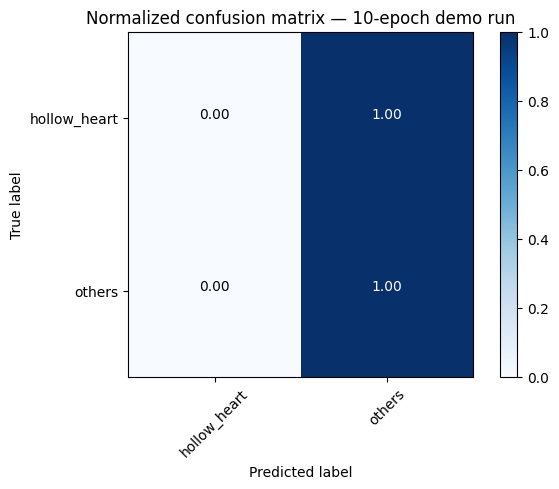

In [ ]:
import itertools
from sklearn.metrics import confusion_matrix
def plot_confusion_matrix(cm, classes, normalize=False, title='Confusion matrix',
                          cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')
    print(cm)
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title); plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45); plt.yticks(tick_marks, classes)
    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout(); plt.ylabel('True label'); plt.xlabel('Predicted label')

cm = confusion_matrix(pred_df['Real'], pred_df['Pred value'])
plt.figure()
plot_confusion_matrix(cm, classes=class_names, normalize=True,
                      title=f'Normalized confusion matrix — 10-epoch demo run')
plt.savefig(MODEL_FOLDER + 'confusion_matrix.png', dpi=120)
plt.show()

**Cell — performance summary table and CSV export.** Compiles the authors' `Performance.csv`
metrics for this run (accuracy, correct/incorrect counts per class, average inference time)
and writes a local CSV, as `test_models.py` does for every saved model.

**セル14: 著者の Performance.csv 相当の指標をまとめ、CSV に出力する。**

In [ ]:
correct = int((pred_df['Real'] == pred_df['Pred value']).sum())
n_test = len(pred_df)
perf = pd.DataFrame({'Run': [0], 'Model': [MODEL_FOLDER],
    'Model overall accuracy': [test_acc], 'Model loss': [test_loss],
    'Number of images': [n_test], 'Correct predictions': [correct],
    'Incorrect predictions': [n_test - correct],
    'Correct hollow': [int(((pred_df['Real'] == 0) & (pred_df['Pred value'] == 0)).sum())],
    'Correct other': [int(((pred_df['Real'] == 1) & (pred_df['Pred value'] == 1)).sum())],
    'Incorrect hollow': [int(((pred_df['Real'] == 0) & (pred_df['Pred value'] != 0)).sum())],
    'Incorrect other': [int(((pred_df['Real'] == 1) & (pred_df['Pred value'] != 1)).sum())],
    'Correct (%)': [round(100 * correct / n_test, 2)],
    'Incorrect (%)': [round(100 * (n_test - correct) / n_test, 2)],
    'Average inference time per image (ms)': [round(pred_df['Inference time (ms)'].mean(), 2)]})
perf.to_csv(MODEL_FOLDER + 'Performance.csv', index=False)
display(perf)

,Run,Model,Model overall accuracy,Model loss,Number of images,Correct predictions,Incorrect predictions,Correct hollow,Correct other,Incorrect hollow,Incorrect other,Correct (%),Incorrect (%),Average inference time per image (ms)
0,0,Models/Custom_model_512_run_0/,0.625,0.750992,53,33,20,0,33,20,0,62.26,37.74,140.78


## 6. Interpretation — what this demo does and does not show

**No code cell follows — results summary.** This notebook executed the authors' complete
hollow-heart workflow (label-driven split → albumentations augmentation → custom CNN →
best-checkpoint evaluation → per-image softmax predictions → normalized confusion matrix) on
their 172-image sample with a 10-epoch schedule. The measured accuracy above
applies **only** to this run's small test split and says nothing about the paper's published
performance: the preprint reports 99.12% average (max 100%) test accuracy at 512x512,
averaged over **20 independent runs of up to 400 epochs** on the full 2431-image augmented
dataset. Reproducing those numbers would require the full HuggingFace dataset
(`CollinsW/PotatoHHData`, ~240 MB zip) and GPU-hours of training, out of scope for this demo.

相違点（日本語）: 本デモは 1 ラン・10 エポック・172 枚サンプルであり、論文の
20 ラン × 400 エポック × 2431 枚（拡張後）とは規模が異なります。上記の精度はこの小テスト
分割にのみ有効です。

**Validation record (post-execution markdown edit, 2026-10-28):** this notebook was executed
end-to-end on 2026-10-28 in two fresh Colab runtimes with no cell errors. The outputs above
are from the **T4 GPU** run (mixed_float16, training 35.9 s, saved-model test accuracy
62.50%); the fresh CPU run (float32, training 787.8 s, test accuracy 62.26%) is archived in
the reproduction report. Both runs' saved-model evaluations matched their recorded
`test_results.csv` exactly.